# 03 · The selected configuration

A closer look at the configuration selected in notebook 02: the distribution of each interpretation variable by
cluster, which pairs of clusters differ on what, a representative patient for each cluster, and how CDR is
distributed over the clusters. C1 is shown alongside for comparison.

The selected configuration is read from `results/02_compare_configurations/selection.json`.

In [1]:
import json

%run -i ../src/setup.ipynb

from sklearn.metrics import adjusted_rand_score

CMP = cfg.RESULTS_DIR / "02_compare_configurations"
OUT = cfg.RESULTS_DIR / "03_profile_selected"
OUT.mkdir(parents=True, exist_ok=True)

selection = json.loads((CMP / "selection.json").read_text())
SEL, K = selection["selected"], selection["k"]
df = load_analysis_data()

saved = pd.read_csv(CMP / "labels.csv")
assert (saved["patient_id"] == df["patient_id"]).all()
fit = fit_configuration(SEL, K, df)
labels = relabel_by(df, fit["labels"], "MMSE")
assert (labels == saved[SEL].to_numpy()).all(), "refit differs from notebook 02"
c1_labels = saved["C1"].to_numpy()
print(f"Selected configuration: {SEL}, k = {K}, PSI = {selection['aggregate_psi'][SEL]:.3f}")

Selected configuration: C1-b, k = 4, PSI = 0.527


## 1. Profile table

Median [interquartile range] for continuous variables and the share of each category for the others. Clusters are numbered by decreasing mean MMSE.

In [2]:
def iqr_cell(s, digits):
    q1, q2, q3 = s.quantile([0.25, 0.5, 0.75])
    return f"{q2:.{digits}f} [{q1:.{digits}f}, {q3:.{digits}f}]"

def profile_table(labels):
    rows = {}
    for c in np.sort(np.unique(labels)):
        g = df[labels == c]
        cdr = g["CDR"].value_counts(normalize=True).reindex([0, 0.5, 1, 2], fill_value=0) * 100
        rows[f"Cluster {c}"] = {
            "n (%)": f"{len(g)} ({100 * len(g) / len(df):.0f}%)",
            "Age": iqr_cell(g["Age"], 0),
            "MMSE": iqr_cell(g["MMSE"], 0),
            "nWBV": iqr_cell(g["nWBV"], 3),
            "eTIV (cm³)": iqr_cell(g["eTIV"], 0),
            "Education (1-5)": iqr_cell(g["Educ"], 0),
            "SES (1-5)": iqr_cell(g["SES"], 0),
            "CDR 0 / 0.5 / 1 / 2 (%)": " / ".join(f"{v:.0f}" for v in cdr),
            "Men (%)": f"{100 * g['sex'].mean():.0f}",
        }
    return pd.DataFrame(rows)

table = profile_table(labels)
table.to_csv(OUT / f"profile_table_{SEL}.csv")
table

,Cluster 1,Cluster 2,Cluster 3,Cluster 4
n (%),47 (22%),72 (33%),67 (31%),30 (14%)
Age,"54 [48, 59]","74 [70, 82]","78 [73, 84]","78 [76, 85]"
MMSE,"30 [29, 30]","29 [28, 30]","28 [26, 30]","21 [19, 23]"
nWBV,"0.814 [0.794, 0.825]","0.764 [0.735, 0.780]","0.730 [0.707, 0.746]","0.693 [0.673, 0.715]"
eTIV (cm³),"1389 [1326, 1516]","1391 [1335, 1478]","1534 [1400, 1662]","1461 [1330, 1495]"
Education (1-5),"4 [3, 5]","2 [2, 3]","5 [4, 5]","2 [1, 2]"
SES (1-5),"2 [1, 2]","3 [3, 4]","1 [1, 2]","4 [3, 4]"
CDR 0 / 0.5 / 1 / 2 (%),100 / 0 / 0 / 0,69 / 29 / 1 / 0,52 / 37 / 10 / 0,3 / 37 / 53 / 7
Men (%),28,26,43,33


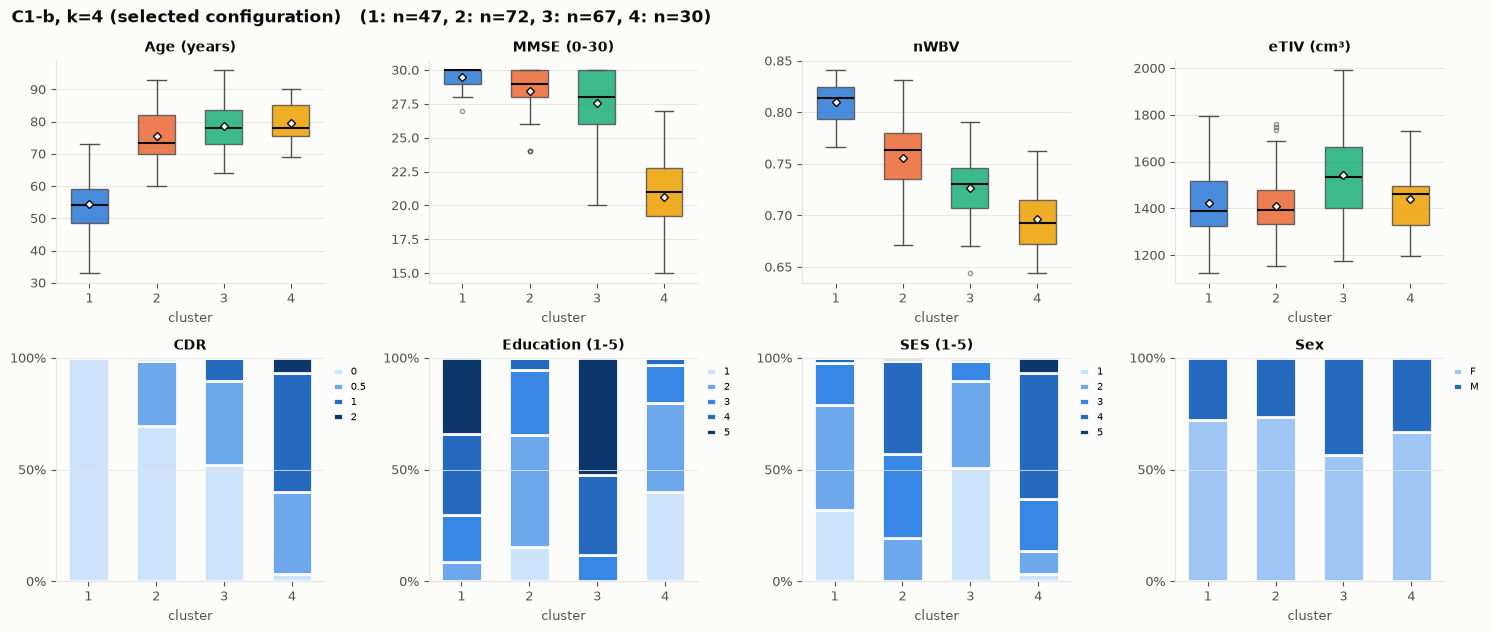

In [3]:
fig = cluster_profile(df, labels, f"{SEL}, k={K} (selected configuration)")
fig.savefig(OUT / f"profile_{SEL}.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Which pairs of clusters differ on what

Each cell is |Cliff's δ| (TVD for sex) between two clusters on one variable.

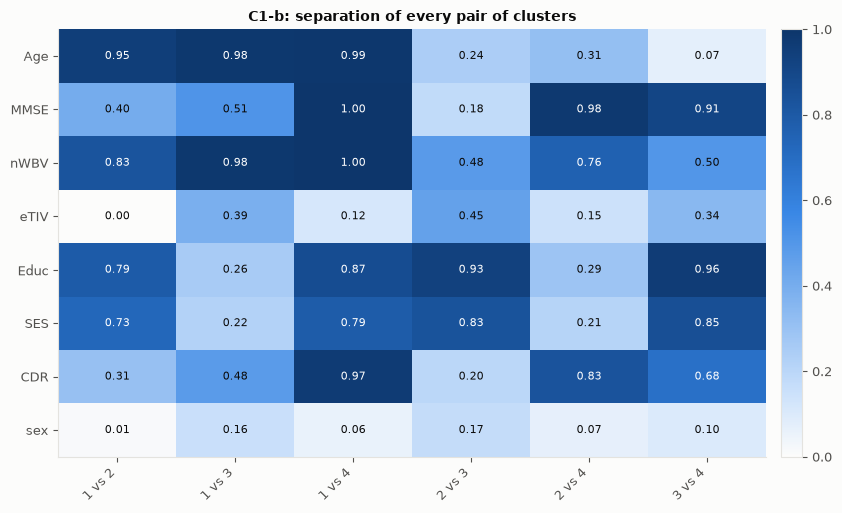

Pairwise Separability report — C1-b
----------------------------------------------------------------------------
Variable Type      Metric        MeanEff Effect      Secondary         Value
----------------------------------------------------------------------------
nWBV   ordinal   cliffs_delta    0.760 large       median_diff       0.066
Educ   ordinal   cliffs_delta    0.683 large       median_diff       1.833
MMSE   ordinal   cliffs_delta    0.662 large       median_diff       4.667
SES    ordinal   cliffs_delta    0.606 large       median_diff       1.667
Age    ordinal   cliffs_delta    0.592 large       median_diff      12.750
CDR    ordinal   cliffs_delta    0.577 large       median_diff       0.500
eTIV   ordinal   cliffs_delta    0.241 small       median_diff      84.167
sex    nominal   TVD             0.094 negligible  mode_mismatch     0.000
----------------------------------------------------------------------------
PAIRWISE SEPARABILITY INDEX (mean)    0.527 large      


In [4]:
report = psi_report(df, labels, SEL)
pairs = pd.DataFrame({v.variable: v.to_frame().set_index("pair")["abs_cliffs_delta" if v.var_kind == "ordinal" else "tvd"]
                      for v in report.per_variable}).T
pairs.columns = [p.replace("(", "").replace(")", "").replace(",", " vs ") for p in pairs.columns]
pairs.to_csv(OUT / f"pairwise_{SEL}.csv")
fig = psi_heatmap(pairs, f"{SEL}: separation of every pair of clusters")
fig.savefig(OUT / f"pairwise_{SEL}.png", dpi=200, bbox_inches="tight")
plt.show()
print(report.summary())

## 3. Representative patients

k-means centroids are averages rather than real patients, so each cluster is represented by the patient closest
to its centroid, together with the next two closest patients.

In [5]:
def representatives(fit, labels, n_neighbours=3):
    X = fit["X"]
    rows = []
    for c in np.sort(np.unique(labels)):
        idx = np.where(labels == c)[0]
        if fit["medoids"] is not None:
            centre = X[[m for m in fit["medoids"] if labels[m] == c][0]]
        else:
            centre = X[idx].mean(axis=0)
        order = idx[np.argsort(np.linalg.norm(X[idx] - centre, axis=1))][:n_neighbours]
        for rank, i in enumerate(order):
            rows.append({"cluster": c, "role": "representative" if rank == 0 else f"neighbour {rank}",
                         "patient": df.loc[i, "patient_id"], "sex": df.loc[i, "M/F"],
                         **{v: df.loc[i, v] for v in ["Age", "MMSE", "CDR", "nWBV", "eTIV", "Educ", "SES"]}})
    return pd.DataFrame(rows)

reps = representatives(fit, labels)
reps.to_csv(OUT / f"representatives_{SEL}.csv", index=False)
reps

,cluster,role,patient,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,representative,OAS1_0345,F,54,30.0,0.0,0.831,1389,4.0,2.0
1,1,neighbour 1,OAS1_0188,M,48,30.0,0.0,0.790,1464,4.0,2.0
2,1,neighbour 2,OAS1_0181,F,49,30.0,0.0,0.820,1316,4.0,2.0
3,2,representative,OAS1_0082,F,75,28.0,0.5,0.776,1407,2.0,3.0
4,2,neighbour 1,OAS1_0001,F,74,29.0,0.0,0.743,1344,2.0,3.0
5,2,neighbour 2,OAS1_0165,F,74,29.0,0.0,0.787,1395,2.0,3.0
6,3,representative,OAS1_0146,F,82,28.0,0.0,0.742,1513,5.0,1.0
7,3,neighbour 1,OAS1_0067,F,71,27.0,1.0,0.730,1549,4.0,1.0
8,3,neighbour 2,OAS1_0180,F,80,30.0,0.0,0.745,1496,4.0,2.0
9,4,representative,OAS1_0134,M,80,20.0,1.0,0.665,1494,2.0,4.0


## 4. CDR by cluster

How the clinical severity scale is distributed over the clusters.

In [6]:
counts = pd.crosstab(pd.Series(labels, name="cluster"), df["CDR"].rename("CDR"), margins=True, margins_name="total")
pct = pd.crosstab(pd.Series(labels, name="cluster"), df["CDR"].rename("CDR"), normalize="index").mul(100).round(0)
counts.to_csv(OUT / f"cdr_composition_{SEL}.csv")
print("Counts:")
display(counts)
print("Row percentages:")
pct

Counts:


CDR,0.0,0.5,1.0,2.0,total
cluster,,,,,
1,47,0,0,0,47
2,50,21,1,0,72
3,35,25,7,0,67
4,1,11,16,2,30
total,133,57,24,2,216


Row percentages:


CDR,0.0,0.5,1.0,2.0
cluster,,,,
1,100.0,0.0,0.0,0.0
2,69.0,29.0,1.0,0.0
3,52.0,37.0,10.0,0.0
4,3.0,37.0,53.0,7.0


## 5. Comparison with C1

ARI = 1 means identical partitions, 0 means no more agreement than chance.

ARI between C1-b and C1: 0.263


C1 cluster,1,2,3,4
C1-b cluster,,,,
1,33,4,10,0
2,1,17,36,18
3,0,39,18,10
4,0,1,1,28


,Cluster 1,Cluster 2,Cluster 3,Cluster 4
n (%),34 (16%),61 (28%),65 (30%),56 (26%)
Age,"52 [47, 55]","80 [74, 86]","72 [67, 80]","75 [71, 81]"
MMSE,"30 [29, 30]","29 [28, 30]","29 [28, 30]","23 [21, 27]"
nWBV,"0.815 [0.792, 0.827]","0.727 [0.700, 0.747]","0.773 [0.751, 0.801]","0.715 [0.687, 0.739]"
eTIV (cm³),"1373 [1327, 1463]","1398 [1301, 1496]","1495 [1390, 1687]","1462 [1366, 1508]"
Education (1-5),"4 [3, 5]","4 [3, 5]","3 [2, 4]","2 [1, 3]"
SES (1-5),"2 [1, 2]","2 [1, 3]","3 [2, 4]","3 [2, 4]"
CDR 0 / 0.5 / 1 / 2 (%),100 / 0 / 0 / 0,70 / 25 / 5 / 0,71 / 25 / 5 / 0,18 / 46 / 32 / 4
Men (%),21,21,48,36


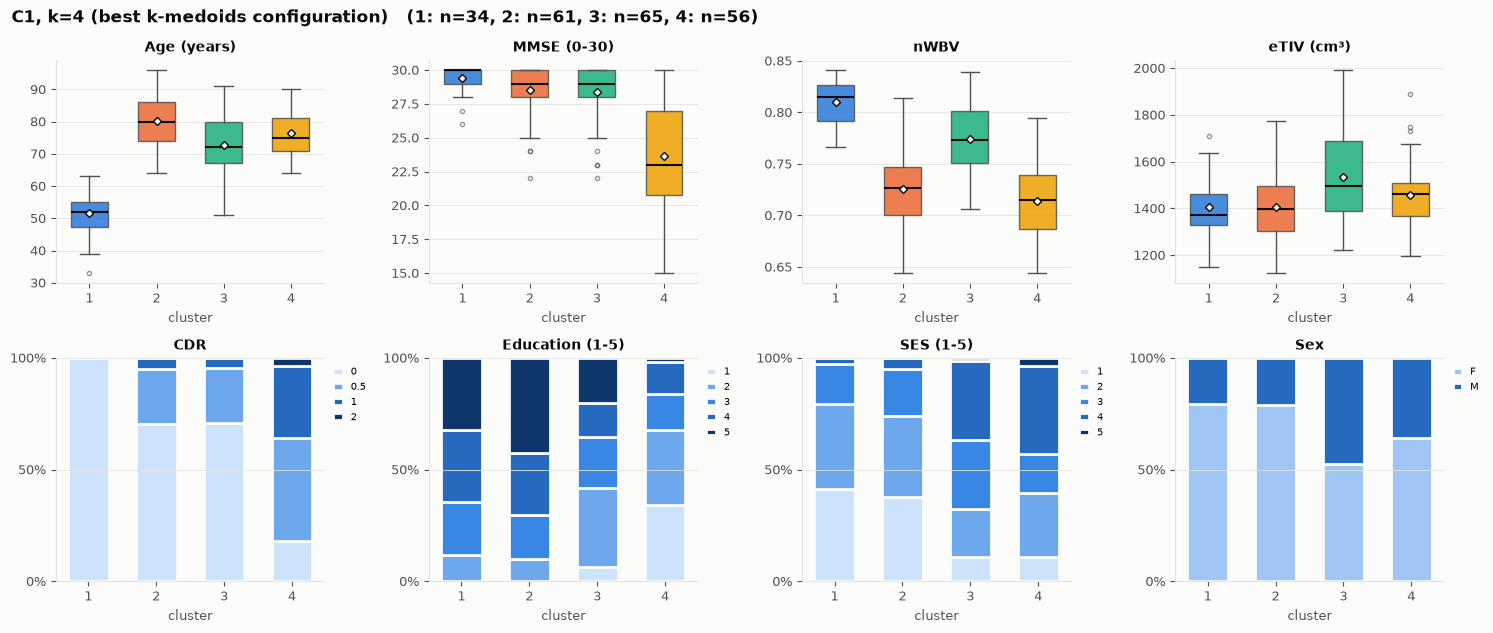

In [7]:
print(f"ARI between {SEL} and C1: {adjusted_rand_score(labels, c1_labels):.3f}")
display(pd.crosstab(pd.Series(labels, name=f"{SEL} cluster"), pd.Series(c1_labels, name="C1 cluster")))
display(profile_table(c1_labels))
fig = cluster_profile(df, c1_labels, f"C1, k={K} (best k-medoids configuration)")
fig.savefig(OUT / "profile_C1.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Interpretation

| | Cluster 1 | Cluster 2 | Cluster 3 | Cluster 4 |
|---|---|---|---|---|
| Label | young, cognitively healthy | older, healthy, lower education | older, highly educated, very mild impairment | cognitively impaired |
| Size | 47 (22%) | 72 (33%) | 67 (31%) | 30 (14%) |
| Age | 54 | 74 | 78 | 78 |
| MMSE | 30 | 29 | 28 | 21 |
| nWBV | 0.814 | 0.764 | 0.730 | 0.693 |
| CDR > 0 | 0% | 31% (almost all 0.5) | 48% (mostly 0.5) | 97% (60% CDR ≥ 1) |
| Education / SES | high / high | low / low | highest / highest | lowest / lowest |

- Age and brain volume separate the young healthy group from all the others (|δ| ≥ 0.95 for Age, ≥ 0.83 for
  nWBV).
- MMSE and CDR separate the impaired group from the rest (MMSE |δ| between 0.91 and 1.00, CDR between 0.68 and
  0.97).
- Clusters 2 and 3 differ mainly in education and socioeconomic status (|δ| = 0.93 and 0.83); cluster 3 is also
  a bit older, with larger heads and slightly lower brain volume and MMSE.
- No pair of clusters differs in sex (TVD ≤ 0.17).

Two remarks. Education and SES are strongly correlated (r = −0.74) and k-means counts that shared direction
twice, which partly explains why it scores higher than C1. And C1 and C1-b agree only partly (ARI = 0.26): both
find a young healthy group and an impaired group, but split the older, non-impaired patients differently
(C1 by age, atrophy and head size, C1-b by education and SES).